# Image Pixel Manipulator using NumPy

## About the Project

 This project uses NumPy to perform basic image operations by changing pixel values.

## Features
1. RGB color demo
2. Image upload and analysis
3. Brightness and darkness adjustment
4. Grayscale conversion
5. Cropping, flipping and RGB channels

**Libraries:** NumPy, Matplotlib, Pillow

## 1. Import Required Libraries

NumPy handles pixel arrays, Matplotlib displays images, and Pillow opens uploaded image files.

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from google.colab import files
import io

print("Required libraries imported successfully.")

Required libraries imported successfully.


## 2. RGB Color-Block Demonstration

This section creates an image with different colours using NumPy.

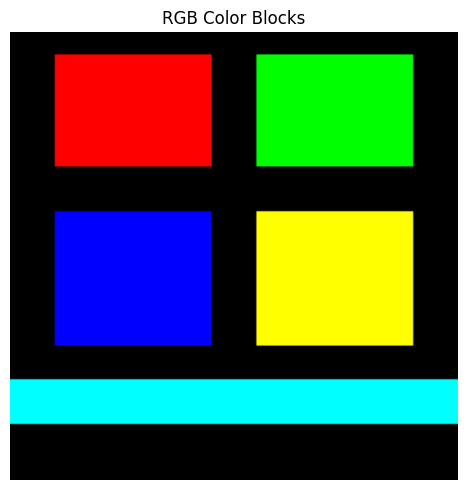

In [4]:
img = np.zeros((200, 200, 3), dtype=np.uint8)

img[10:60, 20:90] = [255, 0, 0]
img[10:60, 110:180] = [0, 255, 0]
img[80:140, 20:90] = [0, 0, 255]
img[80:140, 110:180] = [255, 255, 0]
img[155:175, :] = [0, 255, 255]

plt.figure(figsize=(7, 5))
plt.imshow(img)
plt.title("RGB Color Blocks")
plt.axis("off")
plt.tight_layout()
plt.show()

## 3. Upload and Inspect a Real Image
Upload an image to check its pixel values and basic details using NumPy.

Saving Baz Luhrmann's Film Great Gatsby, love the Art Deco poster design, sharp detail_.jpeg to Baz Luhrmann's Film Great Gatsby, love the Art Deco poster design, sharp detail_.jpeg
Image name: Baz Luhrmann's Film Great Gatsby, love the Art Deco poster design, sharp detail_.jpeg
Image shape (height, width, channels): (1104, 736, 3)
Dimensions: 3
Total pixel values: 2437632
Data type: uint8
Minimum pixel value: 0
Maximum pixel value: 255


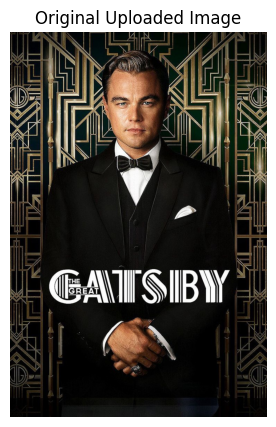

In [13]:
uploaded = files.upload()

if uploaded:
    filename = next(iter(uploaded))
    image = Image.open(io.BytesIO(uploaded[filename])).convert("RGB")
    img_array = np.array(image)

    print("Image name:", filename)
    print("Image shape (height, width, channels):", img_array.shape)
    print("Dimensions:", img_array.ndim)
    print("Total pixel values:", img_array.size)
    print("Data type:", img_array.dtype)
    print("Minimum pixel value:", img_array.min())
    print("Maximum pixel value:", img_array.max())

    plt.figure(figsize=(7, 5))
    plt.imshow(img_array)
    plt.title("Original Uploaded Image")
    plt.axis("off")
    plt.show()
else:
    print("No image uploaded. Run this cell again to select an image.")

## 4. Brightness and Darkness Adjustment

The following code adds or subtracts a brightness value from each pixel. `np.clip()` keeps values between 0 and 255.

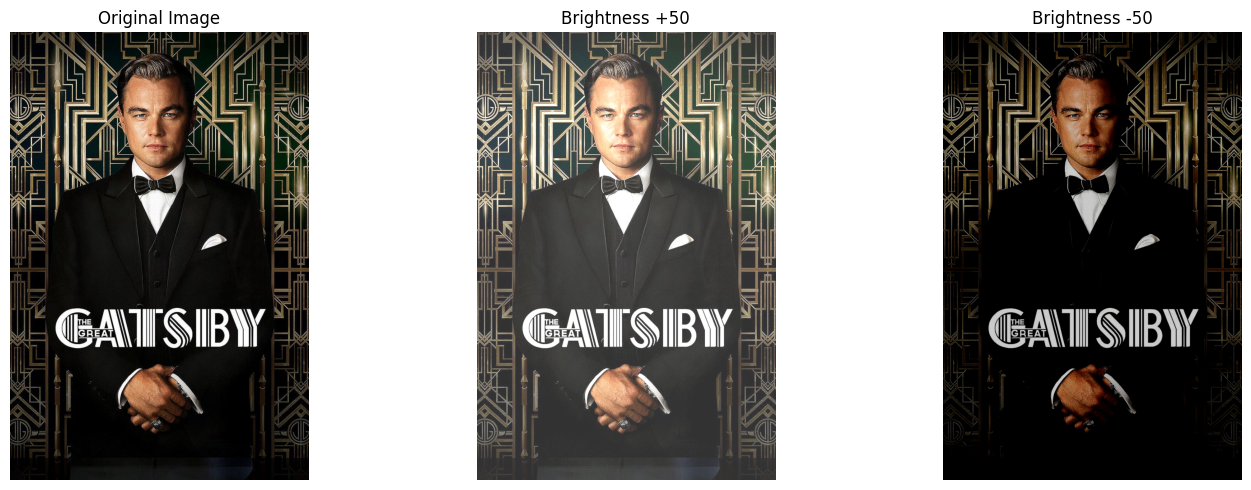

In [14]:
brightness_value = 50

bright_img = np.clip(
    img_array.astype(np.int16) + brightness_value, 0, 255
).astype(np.uint8)

dark_img = np.clip(
    img_array.astype(np.int16) - brightness_value, 0, 255
).astype(np.uint8)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(img_array)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(bright_img)
plt.title("Brightness +50")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(dark_img)
plt.title("Brightness -50")
plt.axis("off")

plt.tight_layout()
plt.show()

## 5. Grayscale Conversion

RGB channels are combined using weighted values to calculate a single intensity value for each pixel.

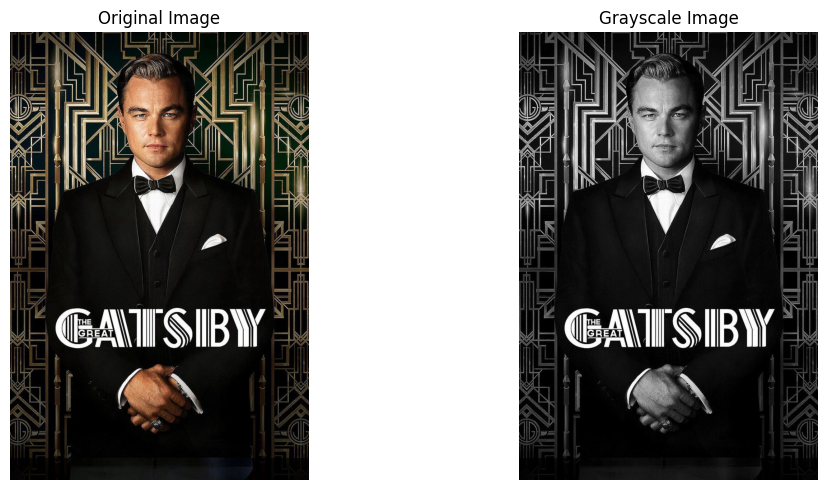

Original shape: (1104, 736, 3)
Grayscale shape: (1104, 736)
Grayscale data type: uint8


In [15]:
gray_img = np.dot(
    img_array[..., :3],
    [0.299, 0.587, 0.114]
).astype(np.uint8)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(img_array)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(gray_img, cmap="gray")
plt.title("Grayscale Image")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Original shape:", img_array.shape)
print("Grayscale shape:", gray_img.shape)
print("Grayscale data type:", gray_img.dtype)

## 6. Cropping, Flipping and RGB Channels

NumPy slicing selects a rectangular image region, reverses the columns for a horizontal flip, and extracts individual RGB channels.

Original: (1104, 736, 3)
Cropped: (130, 160, 3)
Flipped: (1104, 736, 3)
Red channel: (1104, 736)


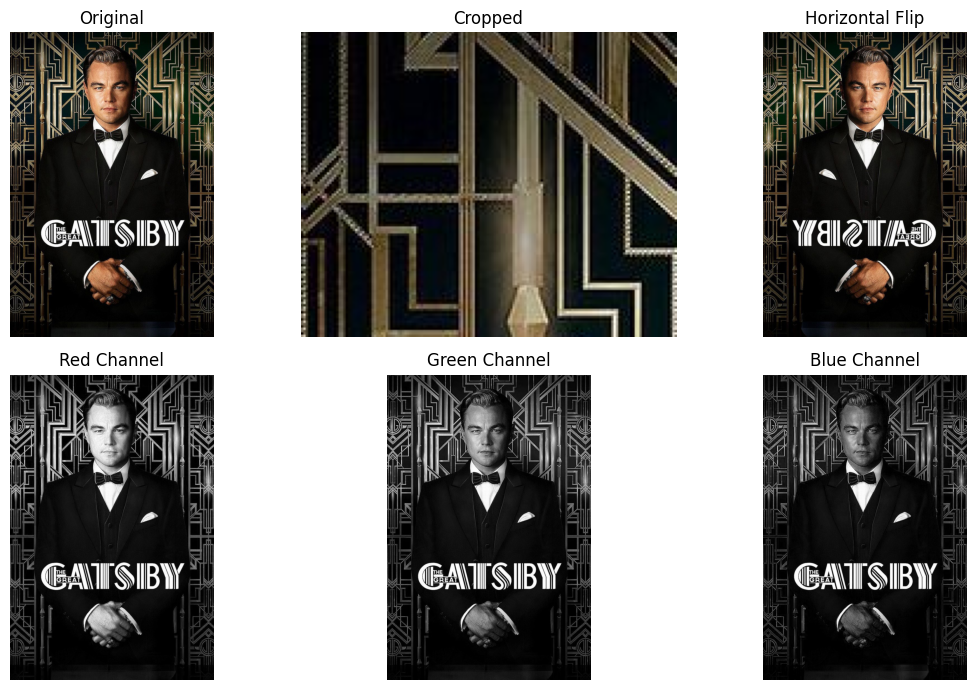

In [16]:
cropped = img_array[10:140, 20:180, :]
flipped = img_array[:, ::-1, :]

red_channel = img_array[:, :, 0]
green_channel = img_array[:, :, 1]
blue_channel = img_array[:, :, 2]

print("Original:", img_array.shape)
print("Cropped:", cropped.shape)
print("Flipped:", flipped.shape)
print("Red channel:", red_channel.shape)

fig, axes = plt.subplots(2, 3, figsize=(12, 7))

axes[0, 0].imshow(img_array)
axes[0, 0].set_title("Original")

axes[0, 1].imshow(cropped)
axes[0, 1].set_title("Cropped")

axes[0, 2].imshow(flipped)
axes[0, 2].set_title("Horizontal Flip")

axes[1, 0].imshow(red_channel, cmap="gray", vmin=0, vmax=255)
axes[1, 0].set_title("Red Channel")

axes[1, 1].imshow(green_channel, cmap="gray", vmin=0, vmax=255)
axes[1, 1].set_title("Green Channel")

axes[1, 2].imshow(blue_channel, cmap="gray", vmin=0, vmax=255)
axes[1, 2].set_title("Blue Channel")

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [21]:
!ls -lah /content/Image-Pixel-Manipulator/

total 1.1M
drwxr-xr-x 3 root root 4.0K Oct 13 21:10 .
drwxr-xr-x 1 root root 4.0K Oct 13 21:10 ..
drwxr-xr-x 8 root root 4.0K Oct 13 21:10 .git
-rw-r--r-- 1 root root 1.1M Oct 13 21:10 Image_Pixel_Manipulator.ipynb
